# Eksploracja danych · Laboratorium 4
## Wykrywanie anomalii w dostawach (spotkanie 1): diagnostyka, IQR, model normy, k-means, Isolation Forest

**Dane:** `dane/dostawy_styczen.csv`: 1500 dostaw ze stycznia 2026 r. (dane syntetyczne).

| Kolumna | Opis |
|---|---|
| `id_dostawy` | identyfikator (**nie** jest cechą) |
| `data` | dzień dostawy (poniedziałek–sobota) |
| `odleglosc_km`, `masa_kg` | odległość trasy i masa przesyłki |
| `ekspres` | 1 = usługa ekspresowa |
| `czas_h`, `opoznienie_h` | czas przejazdu i opóźnienie względem planu [h] |
| `koszt_pln` | koszt dostawy [zł] |
| `etykieta`, `typ_anomalii` | prawda syntetyczna: 45 rekordów zmodyfikowanych celowo. **Tylko do oceny, nigdy jako cecha.** |

**Zasada pracy:** każdą decyzję zapisujemy w komórce tekstowej: co, ile wierszy, dlaczego. Wyniki kontrolne są w karcie zadań.
Przed oddaniem: *Kernel → Restart Kernel and Run All Cells*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
pd.set_option("display.precision", 2)

## Z1. Wczytanie i diagnostyka przed modelowaniem

In [2]:
df = pd.read_csv("dane/dostawy_styczen.csv", parse_dates=["data"])
df["typ_anomalii"] = df["typ_anomalii"].fillna("")
CECHY = ["odleglosc_km", "masa_kg", "ekspres", "czas_h", "opoznienie_h", "koszt_pln"]
y = df["etykieta"].to_numpy()          # tylko do oceny

print("wiersze:", len(df))
print("braki:", df.isna().sum().sum())
print("duplikaty id:", df["id_dostawy"].duplicated().sum())
print("ujemne wartości:", (df[CECHY] < 0).sum().sum())
print("udział ekspres:", round(df["ekspres"].mean(), 3))
df[CECHY].describe()

wiersze: 1500
braki: 0
duplikaty id: 0
ujemne wartości: 0
udział ekspres: 0.176


,odleglosc_km,masa_kg,ekspres,czas_h,opoznienie_h,koszt_pln
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,292.41,195.44,0.18,6.36,1.99,1221.90
std,180.29,161.47,0.38,3.06,4.02,735.66
min,30.90,10.60,0.00,1.45,0.00,270.99
25%,167.28,90.25,0.00,4.20,0.40,783.07
50%,247.75,148.45,0.00,5.63,0.90,1057.89
75%,370.05,240.93,0.00,7.74,1.85,1448.58
max,1200.00,1500.00,1.00,22.30,39.04,11682.82


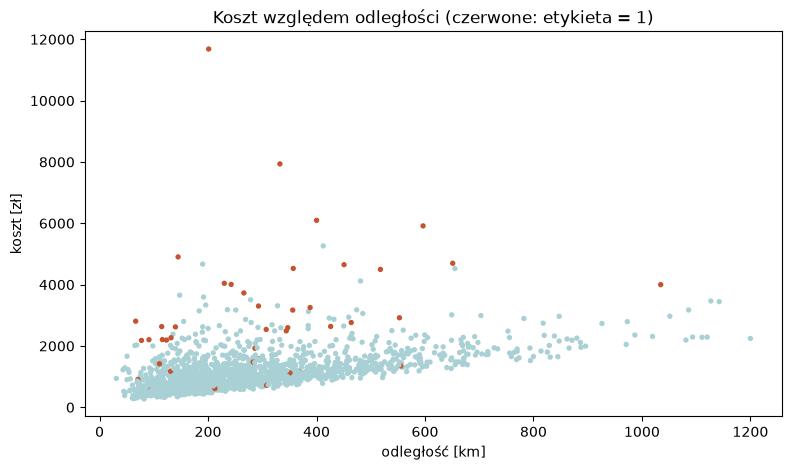

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df.odleglosc_km, df.koszt_pln, s=8, c=np.where(y == 1, "#C4532F", "#A9D0D4"))
ax.set_xlabel("odległość [km]"); ax.set_ylabel("koszt [zł]"); ax.set_title("Koszt względem odległości (czerwone: etykieta = 1)")
plt.show()

**Pytanie:** dlaczego wykres kosztu względem odległości jest ważniejszy niż histogram samego kosztu?

*Odpowiedź:* Koszt zależy od odległości, więc ta sama kwota może być normalna dla długiej trasy i podejrzana dla krótkiej. Histogram samego kosztu patrzy tylko na wartość i tej zależności nie widzi, więc anomalia z wysokim kosztem przy krótkiej trasie ginie wśród drogich, ale normalnych dostaw. Wykres koszt–odległość pokazuje, ile powinna kosztować dostawa przy danym dystansie, i od razu widać punkty, które odstają od tego trendu.

## Z2. Reguła IQR na koszcie (punkt odniesienia)

In [5]:
def metryki(y, alarm, c_alarm=25, c_fn=800):
    y = np.asarray(y).astype(bool); a = np.asarray(alarm).astype(bool)
    tp = (y & a).sum(); fp = (~y & a).sum(); fn = (y & ~a).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0; r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    return {"alarmy": int(a.sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
            "precision": round(float(p), 4), "recall": round(float(r), 4), "F1": round(float(f1), 4), "koszt": int(c_alarm * a.sum() + c_fn * fn)}

def recall_wg_typu(df, alarm):
    t = df["typ_anomalii"]; a = pd.Series(np.asarray(alarm), index=df.index)
    return a[t != ""].groupby(t[t != ""]).mean().round(4)

q1, q3 = df.koszt_pln.quantile([0.25, 0.75])
iqr = q3 - q1; gorny = q3 + 1.5 * iqr

a_iqr = (df.koszt_pln > gorny).to_numpy()
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}, górny próg = {gorny:.2f}")
print(metryki(y, a_iqr))
print(recall_wg_typu(df, a_iqr))
print(df.loc[a_iqr & (y == 0), "odleglosc_km"].mean())
df[(df.typ_anomalii == "koszt +1600 zł") & ~a_iqr]

Q1 = 783.07, Q3 = 1448.58, IQR = 665.51, górny próg = 2446.84
{'alarmy': 73, 'TP': 25, 'FP': 48, 'FN': 20, 'precision': 0.3425, 'recall': 0.5556, 'F1': 0.4237, 'koszt': 17825}
typ_anomalii
koszt +1600 zł      0.67
koszt ×3,5          1.00
opóźnienie +35 h    0.00
dtype: float64
471.9083333333333


,id_dostawy,data,odleglosc_km,masa_kg,ekspres,czas_h,opoznienie_h,koszt_pln,etykieta,typ_anomalii
457,2601-0458,2026-01-12,77.3,140.8,0,2.72,3.88,2181.21,1,koszt +1600 zł
794,2601-0795,2026-01-19,131.8,94.8,1,2.95,0.26,2267.45,1,koszt +1600 zł
867,2601-0868,2026-01-21,123.4,108.6,0,3.97,0.59,2192.77,1,koszt +1600 zł
923,2601-0924,2026-01-22,115.8,140.9,0,3.56,0.42,2209.34,1,koszt +1600 zł
1186,2601-1187,2026-01-27,91.1,135.2,0,3.54,6.06,2204.34,1,koszt +1600 zł


**Pytania:** (1) Ile alarmów IQR to dostawy bez etykiety i jaką mają średnią odległość? (2) Dlaczego IQR na koszcie nie wykrywa ani jednej anomalii typu „opóźnienie +35 h”? (3) Które dostawy „koszt +1600 zł” przeoczył?

*Odpowiedź:* (1) Fałszywych alarmów (dostaw bez etykiety) jest 48, a ich średnia odległość to ok. 471,91 km. IQR reaguje na wysoki koszt, a koszt rośnie z odległością, więc łapie długie trasy, które są po prostu drogie, ale normalne.

(2) Opóźnienie +35 h nie zmienia kosztu dostawy, więc w kolumnie koszt_pln nic się nie wyróżnia i recall dla tego typu wynosi 0%. Reguła patrzy tylko na koszt, a nie na opóźnienie.

(3) Przeoczone „koszt +1600 zł“ to 5 dostaw na krótkich i tanich trasach. Nawet po dodaniu 1600 zł ich koszt nie przekracza progu 2446,84 zł, więc giną wśród normalnych drogich dostaw.

## Z3. Z-score klasyczny i odporny

In [6]:
z = (df.koszt_pln - df.koszt_pln.mean()) / df.koszt_pln.std()
print("|z| > 3:", metryki(y, (z.abs() > 3).to_numpy()))
med = df.koszt_pln.median(); mad = (df.koszt_pln - med).abs().median()
z_odp = (df.koszt_pln - med) / (1.4826 * mad)
print("z odporny > 3,5:", metryki(y, (z_odp > 3.5).to_numpy()))
print("średnia z anomaliami / bez:", round(df.koszt_pln.mean(), 2), round(df.koszt_pln[y == 0].mean(), 2))
print("odchylenie z anomaliami / bez:", round(df.koszt_pln.std(), 2), round(df.koszt_pln[y == 0].std(), 2))
print("mediana z anomaliami / bez:", round(med, 2), round(df.koszt_pln[y == 0].median(), 2))

|z| > 3: {'alarmy': 22, 'TP': 13, 'FP': 9, 'FN': 32, 'precision': 0.5909, 'recall': 0.2889, 'F1': 0.3881, 'koszt': 26150}
z odporny > 3,5: {'alarmy': 50, 'TP': 19, 'FP': 31, 'FN': 26, 'precision': 0.38, 'recall': 0.4222, 'F1': 0.4, 'koszt': 22050}
średnia z anomaliami / bez: 1221.9 1169.33
odchylenie z anomaliami / bez: 735.66 574.08
mediana z anomaliami / bez: 1057.89 1050.82


**Pytanie:** co się stało z odchyleniem standardowym po dodaniu 45 anomalii i dlaczego to „maskuje” część z nich?

*Odpowiedź:* Odchylenie standardowe wzrosło z 574,08 zł (bez anomalii) do 735,66 zł (z anomaliami), bo jest wrażliwe na wartości skrajne. Przez to próg |z| > 3 przesunął się w górę i część anomalii go nie przekracza, więc klasyczny z-score wykrył tylko 22 alarmy (recall 0,29). Anomalie same zawyżyły miarę, którą potem oceniamy anomalie. Mediana i MAD prawie się nie zmieniają, dlatego odporny z-score wykrył 50 alarmów (recall 0,42).

## Z4. Model normy: koszt oczekiwany dla trasy i opóźnienie względem dnia

Anomalia to odstępstwo od **oczekiwania**, a nie od średniej. Krok po kroku:
1. regresja kosztu na odległości, masie, ekspresie (i sobocie),
2. reszta = koszt − koszt oczekiwany,
3. odporny z reszty i opóźnienia; alarm, gdy większy z nich > 3,5.

In [7]:
def odporny_z(x):
    med = x.median(); skala = 1.4826 * (x - med).abs().median()
    return (x - med) / skala

def regula(df, cechy_kosztu, kol_opoznienia, prog=3.5):
    m = LinearRegression().fit(df[cechy_kosztu], df["koszt_pln"])
    reszta = df["koszt_pln"] - m.predict(df[cechy_kosztu])
    wynik = np.maximum(odporny_z(reszta), odporny_z(df[kol_opoznienia]))
    return wynik, m

df["sobota"] = (df.data.dt.weekday == 5).astype(int)
w1, m1 = regula(df, ["odleglosc_km", "masa_kg", "ekspres"], "opoznienie_h")
print("v1:", metryki(y, (w1 > 3.5).to_numpy()))

v1: {'alarmy': 217, 'TP': 45, 'FP': 172, 'FN': 0, 'precision': 0.2074, 'recall': 1.0, 'F1': 0.3435, 'koszt': 5425}


Skąd tyle fałszywych alarmów? Popatrz na opóźnienia **dzień po dniu** (anomalia zbiorowa).

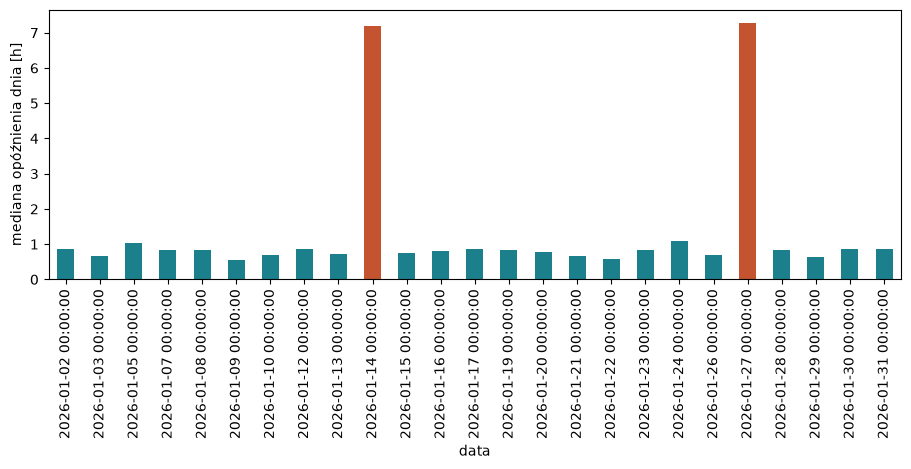

data
2026-01-24    1.08
2026-01-14    7.18
2026-01-27    7.29
Name: opoznienie_h, dtype: float64
FP v1 w dniach ['14.01', '27.01'] : 129 z 172


In [8]:
dzien = df.groupby("data").opoznienie_h.median()
dzien.plot(kind="bar", figsize=(11, 3.5), color=np.where(dzien > 3, "#C4532F", "#1B7F8C"))
plt.ylabel("mediana opóźnienia dnia [h]"); plt.show()
print(dzien.sort_values().tail(3))
fp1 = df[(w1 > 3.5).to_numpy() & (y == 0)]
print("FP v1 w dniach", list(dzien[dzien > 3].index.strftime("%d.%m")), ":", fp1.data.isin(dzien[dzien > 3].index).sum(), "z", len(fp1))

In [9]:
df["opoznienie_wzgl_dnia"] = df.opoznienie_h - df.groupby("data").opoznienie_h.transform("median")
w3, m3 = regula(df, ["odleglosc_km", "masa_kg", "ekspres", "sobota"], "opoznienie_wzgl_dnia")
a3 = (w3 > 3.5).to_numpy()
print("v3:", metryki(y, a3))
print(recall_wg_typu(df, a3))

v3: {'alarmy': 109, 'TP': 45, 'FP': 64, 'FN': 0, 'precision': 0.4128, 'recall': 1.0, 'F1': 0.5844, 'koszt': 2725}
typ_anomalii
koszt +1600 zł      1.0
koszt ×3,5          1.0
opóźnienie +35 h    1.0
dtype: float64


**Pytania:** (1) Ile fałszywych alarmów usunęła kolumna opóźnienia względem dnia? (2) Co wykrywa współczynnik przy `sobota` (porównaj z kosztem bez soboty)? (3) Czy dostawa ze śnieżnego dnia, opóźniona o 7 h, jest anomalią?

*Odpowiedź:* (1) W v1 było 172 fałszywych alarmów, w v3 jest 64, czyli kolumna opóźnienia względem dnia usunęła 108 fałszywych alarmów (całkowita liczba alarmów spadła z 217 do 109). Większość z nich to dostawy z dni 14.01 i 27.01, kiedy opóźnione były wszystkie dostawy naraz.

(2) Współczynnik przy sobocie wynosi ok. 165 zł: w sobotę dostawa kosztuje średnio o ok. 165 zł więcej niż w dzień powszedni przy tej samej odległości, masie i ekspresie. Bez tej cechy sobotnie dostawy miałyby dodatnią resztę i model zgłaszałby je jako fałszywe alarmy.

(3) Nie, dostawa opóźniona o 7 h w śnieżnym dniu nie jest anomalią dostawy, jeśli w tym dniu opóźnione były wszystkie dostawy. To anomalia zbiorowa (pogoda), a nie błąd pojedynczej dostawy. Opóźnienie względem mediany dnia wynosi wtedy blisko 0, więc v3 jej nie oznacza. Alarmem powinna być dostawa opóźniona znacznie bardziej niż reszta tego dnia.

## Z5. K-means i Isolation Forest na standaryzowanych cechach

In [10]:
X = StandardScaler().fit_transform(df[CECHY])
for k in range(2, 9):
    print(k, round(silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)), 4))

2 0.3693
3 0.4022
4 0.4119
5 0.4339
6 0.3504
7 0.361
8 0.361


In [11]:
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
w_km = km.transform(X).min(axis=1)                # odległość do najbliższego centroidu
iforest = IsolationForest(n_estimators=300, random_state=0).fit(X)
w_if = -iforest.score_samples(X)                  # wyżej = bardziej nietypowy

def top(wynik, n):
    a = np.zeros(len(wynik), dtype=bool); a[np.argsort(-np.asarray(wynik), kind="stable")[:n]] = True
    return a

BUDZET = 60
for nazwa, w in [("IQR koszt", df.koszt_pln.to_numpy()), ("Model normy", w3.to_numpy()), ("K-means", w_km), ("Isolation Forest", w_if)]:
    print(f"{nazwa:18s}", metryki(y, top(w, BUDZET)))

IQR koszt          {'alarmy': 60, 'TP': 22, 'FP': 38, 'FN': 23, 'precision': 0.3667, 'recall': 0.4889, 'F1': 0.419, 'koszt': 19900}
Model normy        {'alarmy': 60, 'TP': 45, 'FP': 15, 'FN': 0, 'precision': 0.75, 'recall': 1.0, 'F1': 0.8571, 'koszt': 1500}
K-means            {'alarmy': 60, 'TP': 13, 'FP': 47, 'FN': 32, 'precision': 0.2167, 'recall': 0.2889, 'F1': 0.2476, 'koszt': 27100}
Isolation Forest   {'alarmy': 60, 'TP': 20, 'FP': 40, 'FN': 25, 'precision': 0.3333, 'recall': 0.4444, 'F1': 0.381, 'koszt': 21500}


In [12]:
for c in (0.01, 0.03, 0.05, 0.10):
    m = IsolationForest(n_estimators=300, contamination=c, random_state=0).fit(X)
    print("contamination", c, "→ alarmów:", (m.predict(X) == -1).sum())

contamination 0.01 → alarmów: 15
contamination 0.03 → alarmów: 45
contamination 0.05 → alarmów: 75
contamination 0.1 → alarmów: 150


**Pytania:** (1) Dlaczego budżet alarmów (60 dostaw miesięcznie) jest uczciwszym porównaniem niż `contamination=0.03`? (2) Które typy anomalii widzi Isolation Forest, a których nie? (`recall_wg_typu`)

*Odpowiedź:* (1) Budżet 60 dostaw miesięcznie odpowiada realnej przepustowości kontroli, bo tyle dostaw ktoś faktycznie może sprawdzić. Parametr contamination to założenie o odsetku anomalii, którego z góry nie znamy, i od jego wartości zależy liczba alarmów: 0.01 daje 15 alarmów, 0.03 daje 45, 0.05 daje 75, a 0.10 aż 150. Żadna z tych wartości nie daje 60 alarmów, które da się realnie sprawdzić. Budżet daje uczciwe porównanie, bo każda metoda ma dokładnie tyle samo alarmów (60) i różni się tylko jakością wskazań: model normy ma recall 1.0 i F1 0.8571, Isolation Forest recall 0.4444 i F1 0.381, a K-means recall 0.2889 i F1 0.2476.

(2) Isolation Forest wykrywa anomalie wyraźnie odstające, czyli takie, w których jedna lub kilka cech ma wartości skrajne (np. bardzo wysoki koszt przy małej wadze lub krótkim dystansie), bo takie punkty łatwo odizolować w kilku podziałach drzewa. Nie wykrywa anomalii subtelnych, w których każda cecha z osobna mieści się w normalnym zakresie, a nietypowa jest dopiero zależność między nimi (np. lekko zawyżona stawka). Potwierdza to jego niski recall (0.4444, wykrył tylko 20 z 45 anomalii), podczas gdy model normy, który uwzględnia zależności między cechami, wykrył wszystkie 45.

## Z6. Tabela wyników i ranking

In [13]:
wyniki = df[["id_dostawy", "data"] + CECHY].copy()
wyniki["model_normy"] = w3.to_numpy()
wyniki["kmeans"] = w_km
wyniki["isolation_forest"] = w_if

rangi = wyniki[["model_normy", "kmeans", "isolation_forest"]].rank(ascending=False)
wyniki["ranga_srednia"] = rangi.mean(axis=1)   # niższa = bardziej podejrzana

wyniki = wyniki.sort_values("ranga_srednia")
wyniki.to_csv("wyniki_styczen.csv", index=False)
wyniki.head(10)

,id_dostawy,data,odleglosc_km,masa_kg,ekspres,czas_h,opoznienie_h,koszt_pln,model_normy,kmeans,isolation_forest,ranga_srednia
1085,2601-1086,2026-01-24,201.2,926.5,1,4.42,1.11,11682.82,101.06,14.18,0.70,1.67
78,2601-0079,2026-01-03,332.5,521.0,0,7.20,0.42,7935.88,69.16,8.30,0.61,18.33
335,2601-0336,2026-01-09,596.5,214.5,0,11.47,0.42,5915.29,51.54,5.26,0.62,19.33
606,2601-0607,2026-01-15,1034.6,173.3,1,15.66,0.64,3999.58,16.85,4.78,0.69,22.67
1449,2601-1450,2026-01-31,400.1,270.7,0,8.33,1.81,6096.88,54.23,5.60,0.59,23.67
1241,2601-1242,2026-01-28,242.6,695.4,1,5.45,1.85,4007.51,15.91,5.00,0.64,29.33
1358,2601-1359,2026-01-30,651.1,58.0,0,13.12,0.68,4696.48,41.06,3.93,0.62,33.33
1215,2601-1216,2026-01-27,195.8,1057.5,0,4.06,10.74,3334.24,4.42,6.35,0.66,35.50
1452,2601-1453,2026-01-31,481.1,834.7,0,10.08,0.09,4118.97,6.73,4.48,0.63,36.67
1075,2601-1076,2026-01-24,555.4,50.6,0,11.23,36.01,1347.98,44.66,3.20,0.63,37.00


## Z7. Hipotezy biznesowe

Zapisz trzy hipotezy, co mogło się stać z dostawami z czołówki rankingu (np. błąd stawki, zła jednostka, awaria pojazdu), i jak je sprawdzić (kogo zapytać, jaki dokument).

*Odpowiedź:* Hipoteza 1: błąd stawki lub jednostki na fakturze (typ „koszt x3,5").
Dowody: IQR wykrywa ten typ w 100% (recall 1.00), a na wykresie koszt–odległość to czerwone punkty mocno ponad resztą, np. ok. 11 700 zł przy trasie ok. 180 km, gdy normalnie taka trasa kosztuje ok. 1000–2000 zł. Koszt wzrósł ok. 3,5 razy bez zmiany odległości, masy czy ekspresu, więc to wygląda na pomyłkę przy fakturowaniu (zła stawka, stawka za tonę zamiast za km, przesunięty przecinek), a nie na realny koszt przewozu.
Weryfikacja: porównać fakturę z cennikiem i umową z przewoźnikiem, zapytać dział zakupów/księgowość, czy stawka nie została wpisana ręcznie.

Hipoteza 2: dodatkowa opłata doliczona do krótkich, tanich tras (typ „koszt +1600 zł").
Dowody: to 5 przeoczonych przez IQR dostaw (m.in. 2601-0458, 2601-0795, 2601-0868, 2601-0924, 2601-1187) na trasach 77–132 km, masie ok. 95–140 kg, z kosztem ok. 2180–2270 zł. To mniej niż próg IQR (2446,84 zł), więc IQR ich nie widzi, a model normy wykrył wszystkie (recall 1.00), bo dla takiej trasy i wagi oczekiwany koszt jest kilkaset zł niższy. Stały dodatek 1600 zł niezależny od dystansu sugeruje opłatę dodatkową (np. postój, dopłata za zlecenie specjalne, kara umowna lub podwójnie naliczona opłata stała).
Weryfikacja: sprawdzić pozycje na fakturze (czy jest osobna linia z dopłatą), zlecenie transportowe i zapytać spedytora, za co naliczono 1600 zł.

Hipoteza 3: awaria pojazdu lub zdarzenie na trasie (typ „opóźnienie +35 h").
Dowody: IQR wykrywa tylko 0% tego typu (recall 0.00), bo opóźnienie nie zmienia kosztu, a reguła patrzy tylko na koszt. Dopiero model normy, który osobno ocenia opóźnienie, wychwytuje wszystkie (recall 1.0). 35 h to opóźnienie rzędu doby i więcej, czego nie tłumaczy zwykły korek, więc to raczej awaria pojazdu, zatrzymanie na granicy/w magazynie albo brak dokumentów.
Uwaga: 14.01 i 27.01 mediana opóźnienia całego dnia wynosiła ok. 7 h (przy normalnych ok. 1 h). To zdarzenia dotyczące całego dnia (pogoda, awaria systemu, strajk), a nie pojedyncze anomalie, i dlatego pierwsza reguła dała tam 129 z 172 fałszywych alarmów.
Weryfikacja: dziennik zdarzeń i GPS/telematyka pojazdu, zgłoszenia awarii od spedytora, potwierdzenie odbioru (CMR) z datą i godziną, pytanie do dyspozytora, co się działo 14.01 i 27.01.